In [51]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import re
import string

import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.layers import (
    Embedding,
    LSTM,
    Dense,
    Dropout
)

from tensorflow.keras.models import Sequential, load_model

from tensorflow.keras.callbacks import(
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from sklearn.model_selection import train_test_split

import pickle

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

TensorFlow version: 2.22.0-rc0
NumPy version: 2.4.3
Pandas version: 3.0.3


In [52]:
df = pd.read_csv("qoute_dataset.csv")

df.columns

df.head()

df.isnull().sum()

quote     0
Author    0
dtype: int64

In [53]:
df.info()

df.duplicated().sum()

print("Number of unique quotes:", df["quote"].nunique())

print("Number of unique authors:", df["Author"].nunique())

<class 'pandas.DataFrame'>
RangeIndex: 3038 entries, 0 to 3037
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   quote   3038 non-null   str  
 1   Author  3038 non-null   str  
dtypes: str(2)
memory usage: 554.0 KB
Number of unique quotes: 3037
Number of unique authors: 1005


In [54]:
def clean_text(text):
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove punctuation
    text = re.sub(r"[^\w\s]", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply cleaning
df["clean_quote"] = df["quote"].apply(clean_text)

# Display original vs cleaned text
display(df[["quote", "clean_quote"]].head(10))

,quote,clean_quote
0,“The world as we have created it is a process ...,the world as we have created it is a process o...
1,"“It is our choices, Harry, that show what we t...",it is our choices harry that show what we trul...
2,“There are only two ways to live your life. On...,there are only two ways to live your life one ...
3,"“The person, be it gentleman or lady, who has ...",the person be it gentleman or lady who has not...
4,"“Imperfection is beauty, madness is genius and...",imperfection is beauty madness is genius and i...
5,“Try not to become a man of success. Rather be...,try not to become a man of success rather beco...
6,“It is better to be hated for what you are tha...,it is better to be hated for what you are than...
7,"“I have not failed. I've just found 10,000 way...",i have not failed ive just found 10000 ways th...
8,“A woman is like a tea bag; you never know how...,a woman is like a tea bag you never know how s...
9,"“A day without sunshine is like, you know, nig...",a day without sunshine is like you know night


In [55]:
empty_quotes = (df["clean_quote"].str.len() == 0).sum()

print("Empty quotes:", empty_quotes)
print("Total quotes:", len(df))

Empty quotes: 0
Total quotes: 3038


In [56]:
df = df[df["clean_quote"].str.len() > 0].reset_index(drop=True)

print("Final dataset shape:", df.shape)

Final dataset shape: (3038, 3)


In [57]:
df["word_count"] = df["clean_quote"].apply(lambda x: len(x.split()))

print(df["word_count"].describe())

count    3038.000000
mean       29.048716
std        43.849523
min         1.000000
25%        12.000000
50%        17.000000
75%        29.000000
max       746.000000
Name: word_count, dtype: float64


Text(0, 0.5, 'Number of Quotes')

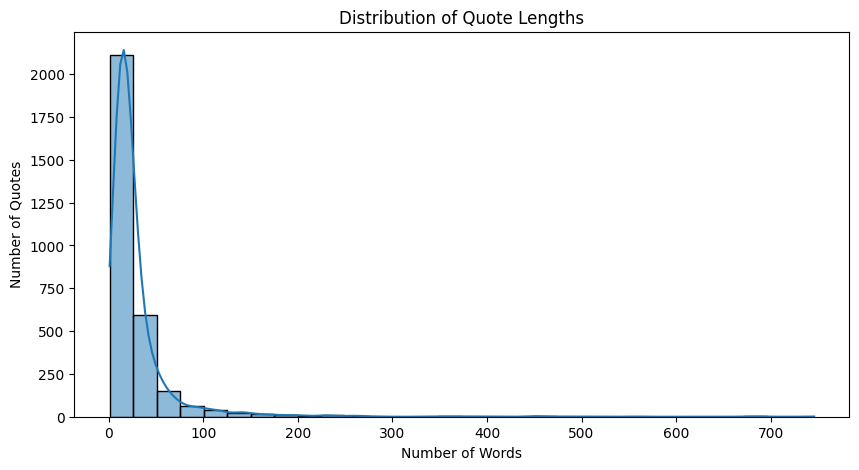

In [58]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["word_count"],
    bins=30,
    kde=True
)

plt.title("Distribution of Quote Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Quotes")


In [59]:
print("Shortest quote:", df["word_count"].min(), "words")
print("Longest quote:", df["word_count"].max(), "words")
print("Average quote:", round(df["word_count"].mean(), 2), "words")

Shortest quote: 1 words
Longest quote: 746 words
Average quote: 29.05 words


In [60]:
corpus = " ".join(df["clean_quote"].tolist())

print("Total characters:", len(corpus))
print("Total words:", len(corpus.split()))

print("\nFirst 500 characters:\n")
print(corpus[:500])

Total characters: 456479
Total words: 88250

First 500 characters:

the world as we have created it is a process of our thinking it cannot be changed without changing our thinking it is our choices harry that show what we truly are far more than our abilities there are only two ways to live your life one is as though nothing is a miracle the other is as though everything is a miracle the person be it gentleman or lady who has not pleasure in a good novel must be intolerably stupid imperfection is beauty madness is genius and its better to be absolutely ridiculou


In [61]:
tokenizer = Tokenizer(
    oov_token="<OOV"
)

tokenizer.fit_on_texts(df["clean_quote"])

total_words = len(tokenizer.word_index) + 1

print("Vocabulary size:", total_words)

Vocabulary size: 8724


In [62]:
print(list(tokenizer.word_index.items())[:20])

[('<OOV', 1), ('the', 2), ('you', 3), ('to', 4), ('and', 5), ('a', 6), ('i', 7), ('is', 8), ('of', 9), ('that', 10), ('it', 11), ('in', 12), ('be', 13), ('not', 14), ('are', 15), ('your', 16), ('have', 17), ('for', 18), ('but', 19), ('we', 20)]


In [63]:
sequences = tokenizer.texts_to_sequences(df["clean_quote"])

print("Number of sequences:", len(sequences))

print("\nExample:")
print(sequences[0])

Number of sequences: 3038

Example:
[2, 63, 30, 20, 17, 938, 11, 8, 6, 1144, 9, 71, 286, 11, 147, 13, 805, 106, 742, 71, 286]


In [64]:
input_sequences = []

for sequence in sequences:

    # Need at least 2 words
    if len(sequence) < 2:
        continue

    for i in range(1, len(sequence)):

        # Take progressively larger sequences
        ngram = sequence[:i + 1]

        # Limit sequence length to 20 words
        if len(ngram) > 20:
            ngram = ngram[-20:]

        input_sequences.append(ngram)


print("Total training sequences:", len(input_sequences))

Total training sequences: 85212


In [65]:
max_sequence_length = max(len(seq) for seq in input_sequences)

print("Maximum sequence length:", max_sequence_length)

Maximum sequence length: 20


In [66]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

input_sequences = np.array(
    pad_sequences(
        input_sequences,
        maxlen=max_sequence_length,
        padding="pre"
    )
)

print("Shape:", input_sequences.shape)

Shape: (85212, 20)


In [67]:
X = input_sequences[:, :-1]
y = input_sequences[:, -1]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (85212, 19)
y shape: (85212,)


In [68]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.10,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)

print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (76690, 19)
X_val: (8522, 19)
y_train: (76690,)
y_val: (8522,)


In [69]:
# ==========================================
# 14. BUILD LSTM MODEL
# ==========================================

model = Sequential([
    
    # Convert word IDs into dense vectors
    Embedding(
        input_dim=total_words,
        output_dim=128,
        input_length=X_train.shape[1]
    ),

    # Learn word relationships
    LSTM(128, return_sequences=True),

    Dropout(0.2),

    # Learn higher-level sequence patterns
    LSTM(64),

    Dropout(0.2),

    # Predict next word
    Dense(total_words, activation="softmax")
])

model.summary()

c:\Users\sambo\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [70]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [72]:
# ==========================================
# 16. CALLBACKS
# ==========================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_lstm_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [39]:
history = model.fit(
    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=5,
    batch_size=128,

    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ],

    verbose=1
)

Epoch 1/5
600/600 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.0409 - loss: 6.5142
Epoch 1: val_loss improved from None to 6.53186, saving model to best_lstm_model.keras

Epoch 1: finished saving model to best_lstm_model.keras
600/600 ━━━━━━━━━━━━━━━━━━━━ 57s 94ms/step - accuracy: 0.0409 - loss: 6.5142 - val_accuracy: 0.0426 - val_loss: 6.5319 - learning_rate: 0.0010
Epoch 2/5
599/600 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.0510 - loss: 6.3198
Epoch 2: val_loss improved from 6.53186 to 6.43410, saving model to best_lstm_model.keras

Epoch 2: finished saving model to best_lstm_model.keras
600/600 ━━━━━━━━━━━━━━━━━━━━ 57s 95ms/step - accuracy: 0.0510 - loss: 6.3200 - val_accuracy: 0.0610 - val_loss: 6.4341 - learning_rate: 0.0010
Epoch 3/5
600/600 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.0665 - loss: 6.1528
Epoch 3: val_loss improved from 6.43410 to 6.37866, saving model to best_lstm_model.keras

Epoch 3: finished saving model to best_lstm_model.keras
600/600 ━━━━━━━━━━

In [73]:
print("Best Validation Loss:",
      min(history.history["val_loss"]))

print("Best Validation Accuracy:",
      max(history.history["val_accuracy"]))

Best Validation Loss: 6.3390936851501465
Best Validation Accuracy: 0.08002816140651703


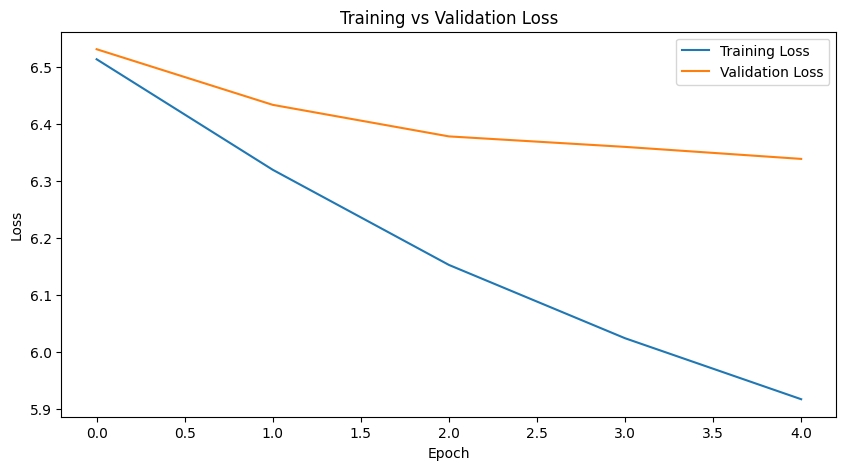

In [74]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.show()

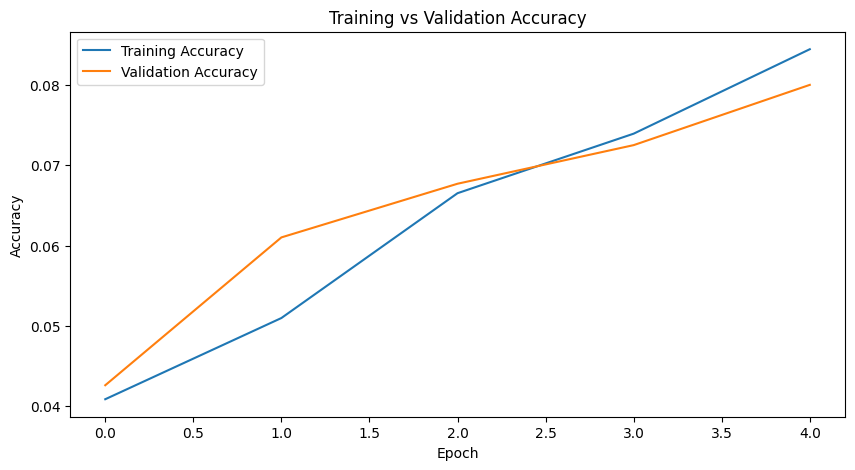

In [75]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.show()

In [76]:
def predict_next_word(seed_text, model, tokenizer, max_sequence_length):

    # Clean input text in the same way as training data
    seed_text = clean_text(seed_text)

    # Convert words → integers
    token_list = tokenizer.texts_to_sequences([seed_text])[0]

    # Keep only the latest words
    token_list = token_list[-(max_sequence_length - 1):]

    # Padding
    token_list = pad_sequences(
        [token_list],
        maxlen=max_sequence_length - 1,
        padding="pre"
    )

    # Predict probabilities
    predicted_probs = model.predict(token_list, verbose=0)

    # Get word ID with highest probability
    predicted_id = np.argmax(predicted_probs, axis=-1)[0]

    # Convert ID → word
    for word, index in tokenizer.word_index.items():
        if index == predicted_id:
            return word

    return None

In [77]:
print(predict_next_word(
    "the meaning of life",
    model,
    tokenizer,
    max_sequence_length
))

weasleygeorges


In [78]:
test_sentences = [
    "the purpose of",
    "life is",
    "the best way",
    "it is",
    "we are",
    "the world is",
    "success is"
]

for sentence in test_sentences:
    prediction = predict_next_word(
        sentence,
        model,
        tokenizer,
        max_sequence_length
    )

    print(f"{sentence} -> {prediction}")

the purpose of -> weasleygeorges
life is -> weasleygeorges
the best way -> weasleygeorges
it is -> weasleygeorges
we are -> weasleygeorges
the world is -> weasleygeorges
success is -> weasleygeorges


In [80]:
# ==========================================
# 20. MULTI-WORD TEXT GENERATION
# ==========================================

def generate_text(seed_text, next_words, model, tokenizer, max_sequence_length):

    generated_text = seed_text

    for _ in range(next_words):

        # Convert current text → sequence
        token_list = tokenizer.texts_to_sequences(
            [generated_text]
        )[0]

        # Keep only the latest words
        token_list = token_list[-(max_sequence_length - 1):]

        # Padding
        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_length - 1,
            padding="pre"
        )

        # Predict next word
        predicted_probs = model.predict(
            token_list,
            verbose=0
        )

        predicted_id = np.argmax(
            predicted_probs,
            axis=-1
        )[0]

        # Convert ID → word
        predicted_word = None

        for word, index in tokenizer.word_index.items():

            if index == predicted_id:
                predicted_word = word
                break

        # If no word found, stop
        if predicted_word is None:
            break

        # Add predicted word
        generated_text += " " + predicted_word

    return generated_text

In [81]:
result = generate_text(
    "the purpose of",
    10,
    model,
    tokenizer,
    max_sequence_length
)

print(result)

the purpose of weasleygeorges weasleygeorges weasleygeorges weasleygeorges weasleygeorges weasleygeorges weasleygeorges weasleygeorges afternoon scar


### GRU model-

In [83]:
from tensorflow.keras.layers import GRU

In [100]:
# ==========================================
# STRONGER GRU MODEL
# ==========================================

gru_model = Sequential([

    Embedding(
        input_dim=total_words,
        output_dim=200,
        input_length=X_train.shape[1]
    ),

    GRU(
        256,
        return_sequences=True,
        dropout=0.15,
        recurrent_dropout=0.15
    ),

    GRU(
        128,
        return_sequences=True,
        dropout=0.15,
        recurrent_dropout=0.15
    ),

    GRU(
        64,
        dropout=0.15,
        recurrent_dropout=0.15
    ),

    Dense(
        128,
        activation="relu"
    ),

    Dropout(0.2),

    Dense(
        total_words,
        activation="softmax"
    )
])

gru_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_3 (GRU)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_4 (GRU)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [101]:
gru_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [102]:
gru_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

gru_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-5,
    verbose=1
)

gru_checkpoint = ModelCheckpoint(
    "best_gru_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [103]:
gru_history = gru_model.fit(
    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=10,
    batch_size=128,

    callbacks=[
        gru_early_stopping,
        gru_reduce_lr,
        gru_checkpoint
    ],

    verbose=1
)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - accuracy: 0.0374 - loss: 6.7517
Epoch 1: val_loss improved from None to 6.62500, saving model to best_gru_model.keras

Epoch 1: finished saving model to best_gru_model.keras
600/600 ━━━━━━━━━━━━━━━━━━━━ 157s 238ms/step - accuracy: 0.0374 - loss: 6.7517 - val_accuracy: 0.0366 - val_loss: 6.6250 - learning_rate: 0.0010
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.0399 - loss: 6.5382
Epoch 2: val_loss improved from 6.62500 to 6.53944, saving model to best_gru_model.keras

Epoch 2: finished saving model to best_gru_model.keras
600/600 ━━━━━━━━━━━━━━━━━━━━ 125s 208ms/step - accuracy: 0.0399 - loss: 6.5382 - val_accuracy: 0.0462 - val_loss: 6.5394 - learning_rate: 0.0010
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - accuracy: 0.0611 - loss: 6.2669
Epoch 3: val_loss improved from 6.53944 to 6.33138, saving model to best_gru_model.keras

Epoch 3: finished saving model to best_gru_model.keras
600/600 ━━━━━━

In [105]:
def sample_word(predictions, temperature=0.7, top_k=10):

    predictions = np.asarray(predictions).astype("float64")

    # Prevent log(0)
    predictions = np.log(predictions + 1e-10)

    # Apply temperature
    predictions = predictions / temperature

    # Convert back to probabilities
    predictions = np.exp(predictions)
    predictions = predictions / np.sum(predictions)

    # Select top-k candidates
    top_indices = np.argsort(predictions)[-top_k:]

    top_probs = predictions[top_indices]
    top_probs = top_probs / np.sum(top_probs)

    # Randomly select one word
    predicted_id = np.random.choice(
        top_indices,
        p=top_probs
    )

    return predicted_id

In [106]:
index_to_word = {
    index: word
    for word, index in tokenizer.word_index.items()
}

In [107]:
def generate_text_gru(
    seed_text,
    next_words,
    model,
    tokenizer,
    max_sequence_length,
    temperature=0.7,
    top_k=10
):

    generated_text = clean_text(seed_text)

    for _ in range(next_words):

        token_list = tokenizer.texts_to_sequences(
            [generated_text]
        )[0]

        token_list = token_list[-(max_sequence_length - 1):]

        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_length - 1,
            padding="pre"
        )

        # Get probability distribution
        predictions = model.predict(
            token_list,
            verbose=0
        )[0]

        # Sample instead of using argmax
        predicted_id = sample_word(
            predictions,
            temperature=temperature,
            top_k=top_k
        )

        predicted_word = index_to_word.get(predicted_id)

        if predicted_word is None:
            break

        generated_text += " " + predicted_word

    return generated_text

In [116]:
result = generate_text_gru(
    "knowledge is",
    10,
    gru_model,
    tokenizer,
    max_sequence_length,
    temperature=0.7,
    top_k=10
)

print(result)

knowledge is the one to know that you will have you it


In [117]:
gru_model.save("best_gru_model.keras")

print("GRU model saved successfully!")

GRU model saved successfully!


In [118]:
with open("tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

print("Tokenizer saved successfully!")

Tokenizer saved successfully!


In [119]:
with open("max_len.pkl", "wb") as file:
    pickle.dump(max_sequence_length, file)

print("Max sequence length saved successfully!")

Max sequence length saved successfully!
